# Turbulence Super-Resolution — Data Inspection

Use this notebook to audit datasets, verify normalization, and visualize a few representative samples before any training.

## Setup and Imports

In [1]:
import sys
import json
import warnings
from pathlib import Path

def find_project_root(start: Path, target="models", max_up: int = 8) -> Path:
    root = start.resolve()
    for _ in range(max_up):
        if (root / target).exists():
            return root
        if root.parent == root:
            break
        root = root.parent
    raise FileNotFoundError(f"Could not find '{target}' above {start}")


ROOT = find_project_root(Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


import h5py
import yaml
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm

from utils.experiment_manager import ExperimentManager
from utils.sr_datasets import (
    TemporalStackDataset,
    MultiFieldDataset,
    create_snapshot_splits,
    compute_global_stats,
    compute_multifield_stats,
)
from utils.losses import GradientLoss, SpectralLoss
from utils.physics_losses import PhysicsInformedLoss, compute_vorticity_from_velocity
from utils.metrics import psnr, ssim
from utils.physics import (
    compute_vorticity_2d,
    gradient_magnitude_2d,
    laplacian_2d,
    advection_u_dot_grad_omega,
    energy_spectrum_2d,
    pdf_from_field,
)
from models.factory import build_model_from_config, available_models

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 150
plt.rcParams['figure.facecolor'] = 'white'
np.random.seed(42)
torch.manual_seed(42)
warnings.filterwarnings('ignore')

print(f"Project root: {ROOT}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Registered models: {available_models()}")

Project root: /workspaces/jhtdb-ml
PyTorch version: 2.9.0+cu128
CUDA available: True
Registered models: ('edsr', 'hdsc_ms', 'mlp', 'unet', 'unet_meteo')


## Configuration and Workspace

In [2]:
CONFIG_PATH = ROOT / 'configs/sr_unet_meteo_128.yaml'  # ← update as needed
with open(CONFIG_PATH) as fp:
    config = yaml.safe_load(fp)

print('Configuration loaded from:', CONFIG_PATH)
print(json.dumps({
    'experiment': config['experiment']['name'],
    'model': config['model']['architecture'],
    'component': config['data']['component'],
    'scale_factor': config['model']['scale_factor'],
    'epochs': config['training']['epochs'],
    'batch_size': config['training']['batch_size'],
    'physics_enabled': config['loss']['components'].get('physics', {}).get('enabled', False),
}, indent=2))

exp_cfg = config['experiment']
run_name = exp_cfg.get('run_name')
manager = ExperimentManager(
    task='SR',
    name=exp_cfg['name'],
    base_dir=ROOT / 'work',
    run_name=run_name
)
manager.setup()
manager.save_config(config)

FIGURES_DIR = manager.plots_dir
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print('Working directory:', manager.run_dir)
print('  Plots:', FIGURES_DIR)
print('  Checkpoints:', manager.checkpoints_dir)
if run_name:
    print(f"  (Using fixed run name: {run_name})")


Configuration loaded from: /workspaces/jhtdb-ml/configs/sr_unet_meteo_128.yaml
{
  "experiment": "sr_unet_meteo_isotropic",
  "model": "unet_meteo",
  "component": "omega_z",
  "scale_factor": 4,
  "epochs": 100,
  "batch_size": 32,
  "physics_enabled": true
}
Working directory: /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_20251120_111621
  Plots: /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_20251120_111621/plots
  Checkpoints: /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_20251120_111621/checkpoints


## Data Loading

In [3]:
# Load dataset
h5_path = (ROOT / config['data']['h5_path']).resolve()
print(f"Loading data from: {h5_path}")

fields = {}
times = []
y_values = []

with h5py.File(h5_path, 'r') as h5:
    # Check structure
    top_keys = list(h5.keys())
    print(f"Top-level keys: {top_keys}")
    
    if 'snapshots' in h5:
        # Hierarchical structure
        snapshots = h5['snapshots']
        snap_keys = sorted(snapshots.keys())
        print(f"Found {len(snap_keys)} snapshots")
        
        for key in snap_keys:
            snap = snapshots[key]
            for field_name in ['ux', 'uy', 'uz', 'omega_z']:
                if field_name in snap:
                    fields.setdefault(field_name, []).append(np.asarray(snap[field_name]))
            if 'time' in snap:
                times.append(float(np.asarray(snap['time'])))
            if 'y_value' in snap:
                y_values.append(np.asarray(snap['y_value']))
    else:
        # Flat structure
        for field_name in ['ux', 'uy', 'uz', 'omega_z']:
            if field_name in h5:
                fields[field_name] = [np.asarray(h5[field_name])]
        if 'time' in h5:
            times.append(np.asarray(h5['time']))
        if 'y_value' in h5:
            y_values.append(np.asarray(h5['y_value']))

# Verify required fields
required = ['ux', 'uy', 'omega_z']
missing = [name for name in required if name not in fields]
if missing:
    raise KeyError(f"Missing required fields: {missing}. Available: {list(fields.keys())}")

# Stack into arrays
ux = np.stack(fields['ux'])
uy = np.stack(fields['uy'])
omega = np.stack(fields['omega_z'])
times = np.asarray(times) if times else np.arange(ux.shape[0])
y_values = np.asarray(y_values) if y_values else None

print(f"\nData loaded:")
print(f"  Snapshots: {ux.shape[0]}")
print(f"  Resolution: {ux.shape[1]}×{ux.shape[2]}")
print(f"  Time range: {times[0]:.3f} - {times[-1]:.3f}")
print(f"  Available components: {list(fields.keys())}")

Loading data from: /workspaces/jhtdb-ml/data/raw/isotropic_xy_128/isotropic_xy_128.h5
Top-level keys: ['snapshots']
Found 7992 snapshots

Data loaded:
  Snapshots: 7992
  Resolution: 128×128
  Time range: 0.000 - 9.990
  Available components: ['ux', 'uy', 'uz', 'omega_z']


In [4]:
# Select component for SR (from config) and store ALL fields for physics losses
component = config['data']['component']
component_map = {
    'ux': ux,
    'uy': uy,
    'omega_z': omega,
}

if component not in component_map:
    raise ValueError(f"Component '{component}' not available. Options: {list(component_map.keys())}")

hr_data = component_map[component]  # Shape: (T, 256, 256) - target field for SR

# Store ALL fields for physics-informed training
all_fields = {
    'ux': ux,
    'uy': uy,
    'omega_z': omega
}

# Get grid spacing from config (needed for physics losses)
if 'domain' in config and 'dns_info' in config['domain']:
    dx = config['domain']['dns_info']['effective_resolution']['dx']
    dy = config['domain']['dns_info']['effective_resolution']['dy']
    print(f"\nGrid spacing from config:")
    print(f"  dx = {dx:.6f}")
    print(f"  dy = {dy:.6f}")
else:
    # Fallback: estimate from data shape
    dx = dy = 1.0 / hr_data.shape[1]
    print(f"\nGrid spacing (estimated from data):")
    print(f"  dx = dy = {dx:.6f}")

print(f"\nSelected component for SR: {component}")
print(f"  Shape: {hr_data.shape}")
print(f"  Snapshots: {hr_data.shape[0]}")
print(f"  Resolution: {hr_data.shape[1]}×{hr_data.shape[2]}")
print(f"  Range: [{hr_data.min():.4f}, {hr_data.max():.4f}]")
print(f"  Mean: {hr_data.mean():.4f}, Std: {hr_data.std():.4f}")

print(f"\nAll fields loaded (for physics losses):")
for name, field in all_fields.items():
    print(f"  {name}: {field.shape}, range=[{field.min():.4f}, {field.max():.4f}]")


Grid spacing from config:
  dx = 0.006136
  dy = 0.006136

Selected component for SR: omega_z
  Shape: (7992, 128, 128)
  Snapshots: 7992
  Resolution: 128×128
  Range: [-323.4162, 309.4149]
  Mean: -0.0954, Std: 12.6199

All fields loaded (for physics losses):
  ux: (7992, 128, 128), range=[-2.6636, 2.6615]
  uy: (7992, 128, 128), range=[-3.5655, 2.6271]
  omega_z: (7992, 128, 128), range=[-323.4162, 309.4149]


## Snapshot Splits and Dataset Construction

In [5]:
# =============================================================================
# Create snapshot-wise splits (NO RANDOM SHUFFLING!)
# =============================================================================
train_idx, val_idx, test_idx = create_snapshot_splits(
    total_snapshots=hr_data.shape[0],
    train_snapshots=config['data']['split']['train_snapshots'],
    val_snapshots=config['data']['split']['val_snapshots'],
    test_snapshots=config['data']['split']['test_snapshots']
)

print("Snapshot-wise splits (temporally ordered):")
print(f"  Train: snapshots {train_idx[0]}-{train_idx[-1]} ({len(train_idx)} snapshots)")
print(f"  Val:   snapshots {val_idx[0]}-{val_idx[-1]} ({len(val_idx)} snapshots)")
print(f"  Test:  snapshots {test_idx[0]}-{test_idx[-1]} ({len(test_idx)} snapshots)")

# =============================================================================
# Check if physics-informed training is enabled
# =============================================================================
USE_PHYSICS_DATASET = config['loss']['components'].get('physics', {}).get('enabled', False)

if USE_PHYSICS_DATASET:
    print(f"\n{'='*70}")
    print("PHYSICS-INFORMED DATASET MODE")
    print(f"{'='*70}")
    print("Using MultiFieldDataset (returns ux, uy, omega_z for physics losses)")
    
    # Compute normalization stats for ALL components
    if config['data']['normalization']['method'] == 'global':
        multifield_stats = compute_multifield_stats(ux, uy, omega, train_idx)
        print(f"\nGlobal normalization stats (computed on train set only):")
        for component, (mu, sigma) in multifield_stats.items():
            print(f"  {component}: μ={mu:.6f}, σ={sigma:.6f}")
    else:
        multifield_stats = None
        print(f"\nNormalization: per-snapshot (each snapshot normalized independently)")
    
    # =============================================================================
    # Create datasets using MultiFieldDataset
    # =============================================================================
    temporal_cfg = config['data']['temporal']
    aug_cfg = config['data']['augmentation']
    scale = config['model']['scale_factor']
    
    # Training dataset (with optional temporal stacking and augmentation)
    train_dataset = MultiFieldDataset(
        ux_seq=ux[train_idx],
        uy_seq=uy[train_idx],
        omega_seq=omega[train_idx],
        N=temporal_cfg['num_frames'] if temporal_cfg['enabled'] else 1,
        dt=temporal_cfg.get('frame_spacing', 1),
        scale=scale,
        normalize=config['data']['normalization']['method'],
        stats=multifield_stats,
        transform_config=aug_cfg
    )
    
    # Validation dataset (NO augmentation, NO temporal stacking)
    val_dataset = MultiFieldDataset(
        ux_seq=ux[val_idx],
        uy_seq=uy[val_idx],
        omega_seq=omega[val_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        stats=multifield_stats,
        transform_config={'enabled': False}
    )
    
    # Test dataset (NO augmentation, NO temporal stacking)
    test_dataset = MultiFieldDataset(
        ux_seq=ux[test_idx],
        uy_seq=uy[test_idx],
        omega_seq=omega[test_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        stats=multifield_stats,
        transform_config={'enabled': False}
    )
    
    print(f"\nDatasets created (MultiFieldDataset):")
    print(f"  Train: {len(train_dataset)} samples")
    print(f"  Val:   {len(val_dataset)} samples")
    print(f"  Test:  {len(test_dataset)} samples")
    
    # Get sample to determine sizes
    sample = train_dataset[0]
    lr_sample = sample['lr_omega']
    hr_sample = sample['hr_omega']
    
else:
    print(f"\n{'='*70}")
    print("STANDARD DATASET MODE (no physics losses)")
    print(f"{'='*70}")
    print("Using TemporalStackDataset (returns only selected component)")
    
    # Compute global normalization stats on TRAIN SET ONLY
    mu, sigma = None, None
    if config['data']['normalization']['method'] == 'global':
        mu, sigma = compute_global_stats(hr_data, train_idx)
        print(f"\nGlobal normalization (computed on train set only):")
        print(f"  μ = {mu:.6f}")
        print(f"  σ = {sigma:.6f}")
    else:
        print(f"\nNormalization: per-snapshot (each snapshot normalized independently)")

    # =============================================================================
    # Create datasets using TemporalStackDataset
    # =============================================================================
    temporal_cfg = config['data']['temporal']
    aug_cfg = config['data']['augmentation']
    scale = config['model']['scale_factor']

    # Training dataset (with augmentation and optional temporal stacking)
    train_dataset = TemporalStackDataset(
        HR_seq=hr_data[train_idx],
        N=temporal_cfg['num_frames'] if temporal_cfg['enabled'] else 1,
        dt=temporal_cfg.get('frame_spacing', 1),
        scale=scale,
        normalize=config['data']['normalization']['method'],
        mu=mu,
        sigma=sigma,
        component=component,
        transform_config=aug_cfg
    )

    # Validation dataset (NO augmentation, NO temporal stacking)
    val_dataset = TemporalStackDataset(
        HR_seq=hr_data[val_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        mu=mu,
        sigma=sigma,
        component=component,
        transform_config={'enabled': False}
    )

    # Test dataset (NO augmentation, NO temporal stacking)
    test_dataset = TemporalStackDataset(
        HR_seq=hr_data[test_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        mu=mu,
        sigma=sigma,
        component=component,
        transform_config={'enabled': False}
    )

    print(f"\nDatasets created (TemporalStackDataset):")
    print(f"  Train: {len(train_dataset)} samples")
    print(f"  Val:   {len(val_dataset)} samples")
    print(f"  Test:  {len(test_dataset)} samples")

    # Get sample to determine sizes
    lr_sample, hr_sample = train_dataset[0]

# =============================================================================
# Common setup (works for both dataset types)
# =============================================================================
LR_SIZE = lr_sample.shape[-1]  # Should be 64
HR_SIZE = hr_sample.shape[-1]  # Should be 256
N_FRAMES = lr_sample.shape[0]   # Number of temporal frames (1, 3, or 5)

print(f"\nTraining pair sizes:")
print(f"  LR input:  {lr_sample.shape} ({N_FRAMES} frames × {LR_SIZE}×{LR_SIZE})")
print(f"  HR target: {hr_sample.shape} ({HR_SIZE}×{HR_SIZE})")
print(f"  Scale factor: {HR_SIZE // LR_SIZE}×")

# =============================================================================
# Create data loaders
# =============================================================================
batch_size = config['training']['batch_size']
num_workers = config['training']['num_workers']

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=num_workers)

print(f"\nData loaders created:")
print(f"  Train: {len(train_loader)} batches of size {batch_size}")
print(f"  Val:   {len(val_loader)} batches")
print(f"  Test:  {len(test_loader)} batches")

Snapshot-wise splits (temporally ordered):
  Train: snapshots 0-5993 (5994 snapshots)
  Val:   snapshots 5994-7191 (1198 snapshots)
  Test:  snapshots 7192-7991 (800 snapshots)

PHYSICS-INFORMED DATASET MODE
Using MultiFieldDataset (returns ux, uy, omega_z for physics losses)

Global normalization stats (computed on train set only):
  ux: μ=-0.255835, σ=0.574498
  uy: μ=-0.433888, σ=0.673921
  omega_z: μ=-0.238260, σ=11.741111

Datasets created (MultiFieldDataset):
  Train: 5994 samples
  Val:   1198 samples
  Test:  800 samples

Training pair sizes:
  LR input:  torch.Size([1, 32, 32]) (1 frames × 32×32)
  HR target: torch.Size([128, 128]) (128×128)
  Scale factor: 4×

Data loaders created:
  Train: 188 batches of size 32
  Val:   38 batches
  Test:  800 batches


## Sample LR/HR Pairs

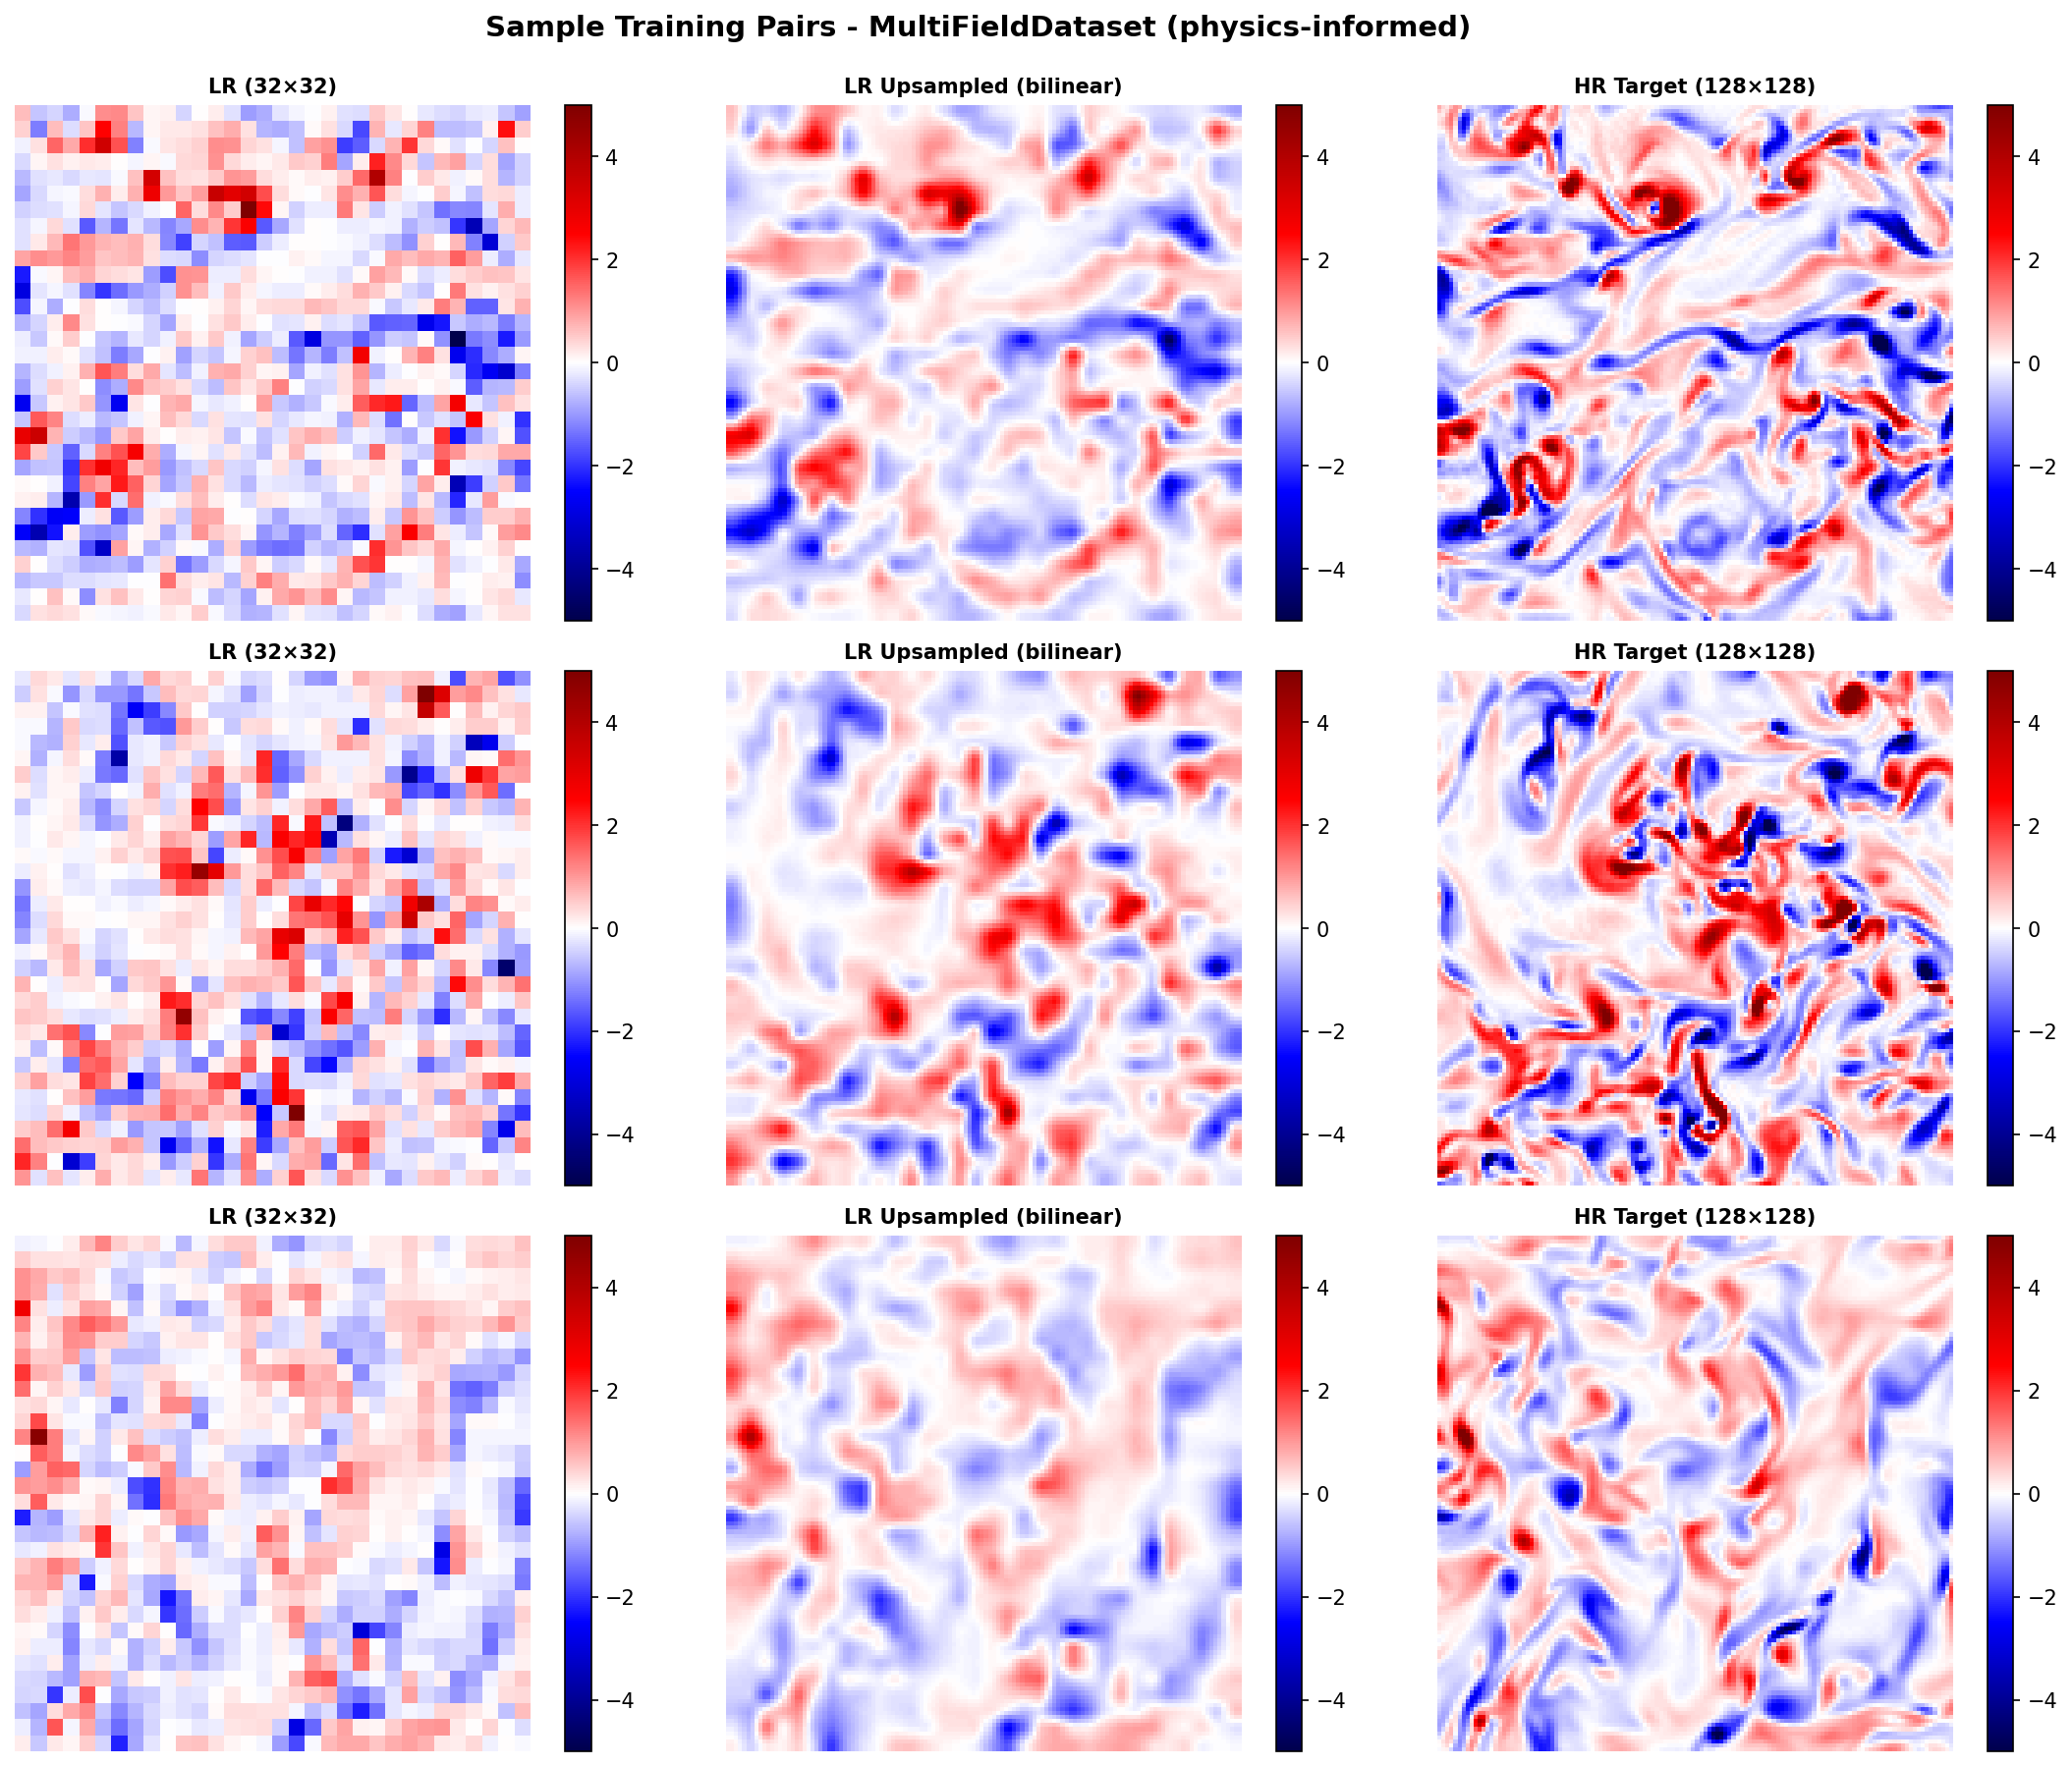

✓ Figure saved: /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_20251120_111621/plots/01_sample_lr_hr_pairs.png
  LR input shape: (1, 32, 32)
  HR target shape: (128, 128)
  Training pairs: 32×32 → 128×128
  Dataset type: MultiFieldDataset (physics-informed)
PHYSICS TERMS ANALYSIS (Sample Training Data)

Field statistics (normalized):
  Vorticity ω:       [    -8.883,      8.583], std=1.179
  Advection (u·∇ω):  [  -988.153,   1051.568], std=101.558
  Diffusion (∇²ω):   [-189900.891, 177857.531], std=21579.885

PHYSICS LOSS SCALE ESTIMATE
Mean squared values:
  E(ω²):       1.40e+00
  E((u·∇ω)²):  1.03e+04
  E((∇²ω)²):   4.66e+08

To match vorticity loss scale, use:
  lambda_adv  ≈ 1.35e-04
  lambda_diff ≈ 3.00e-09


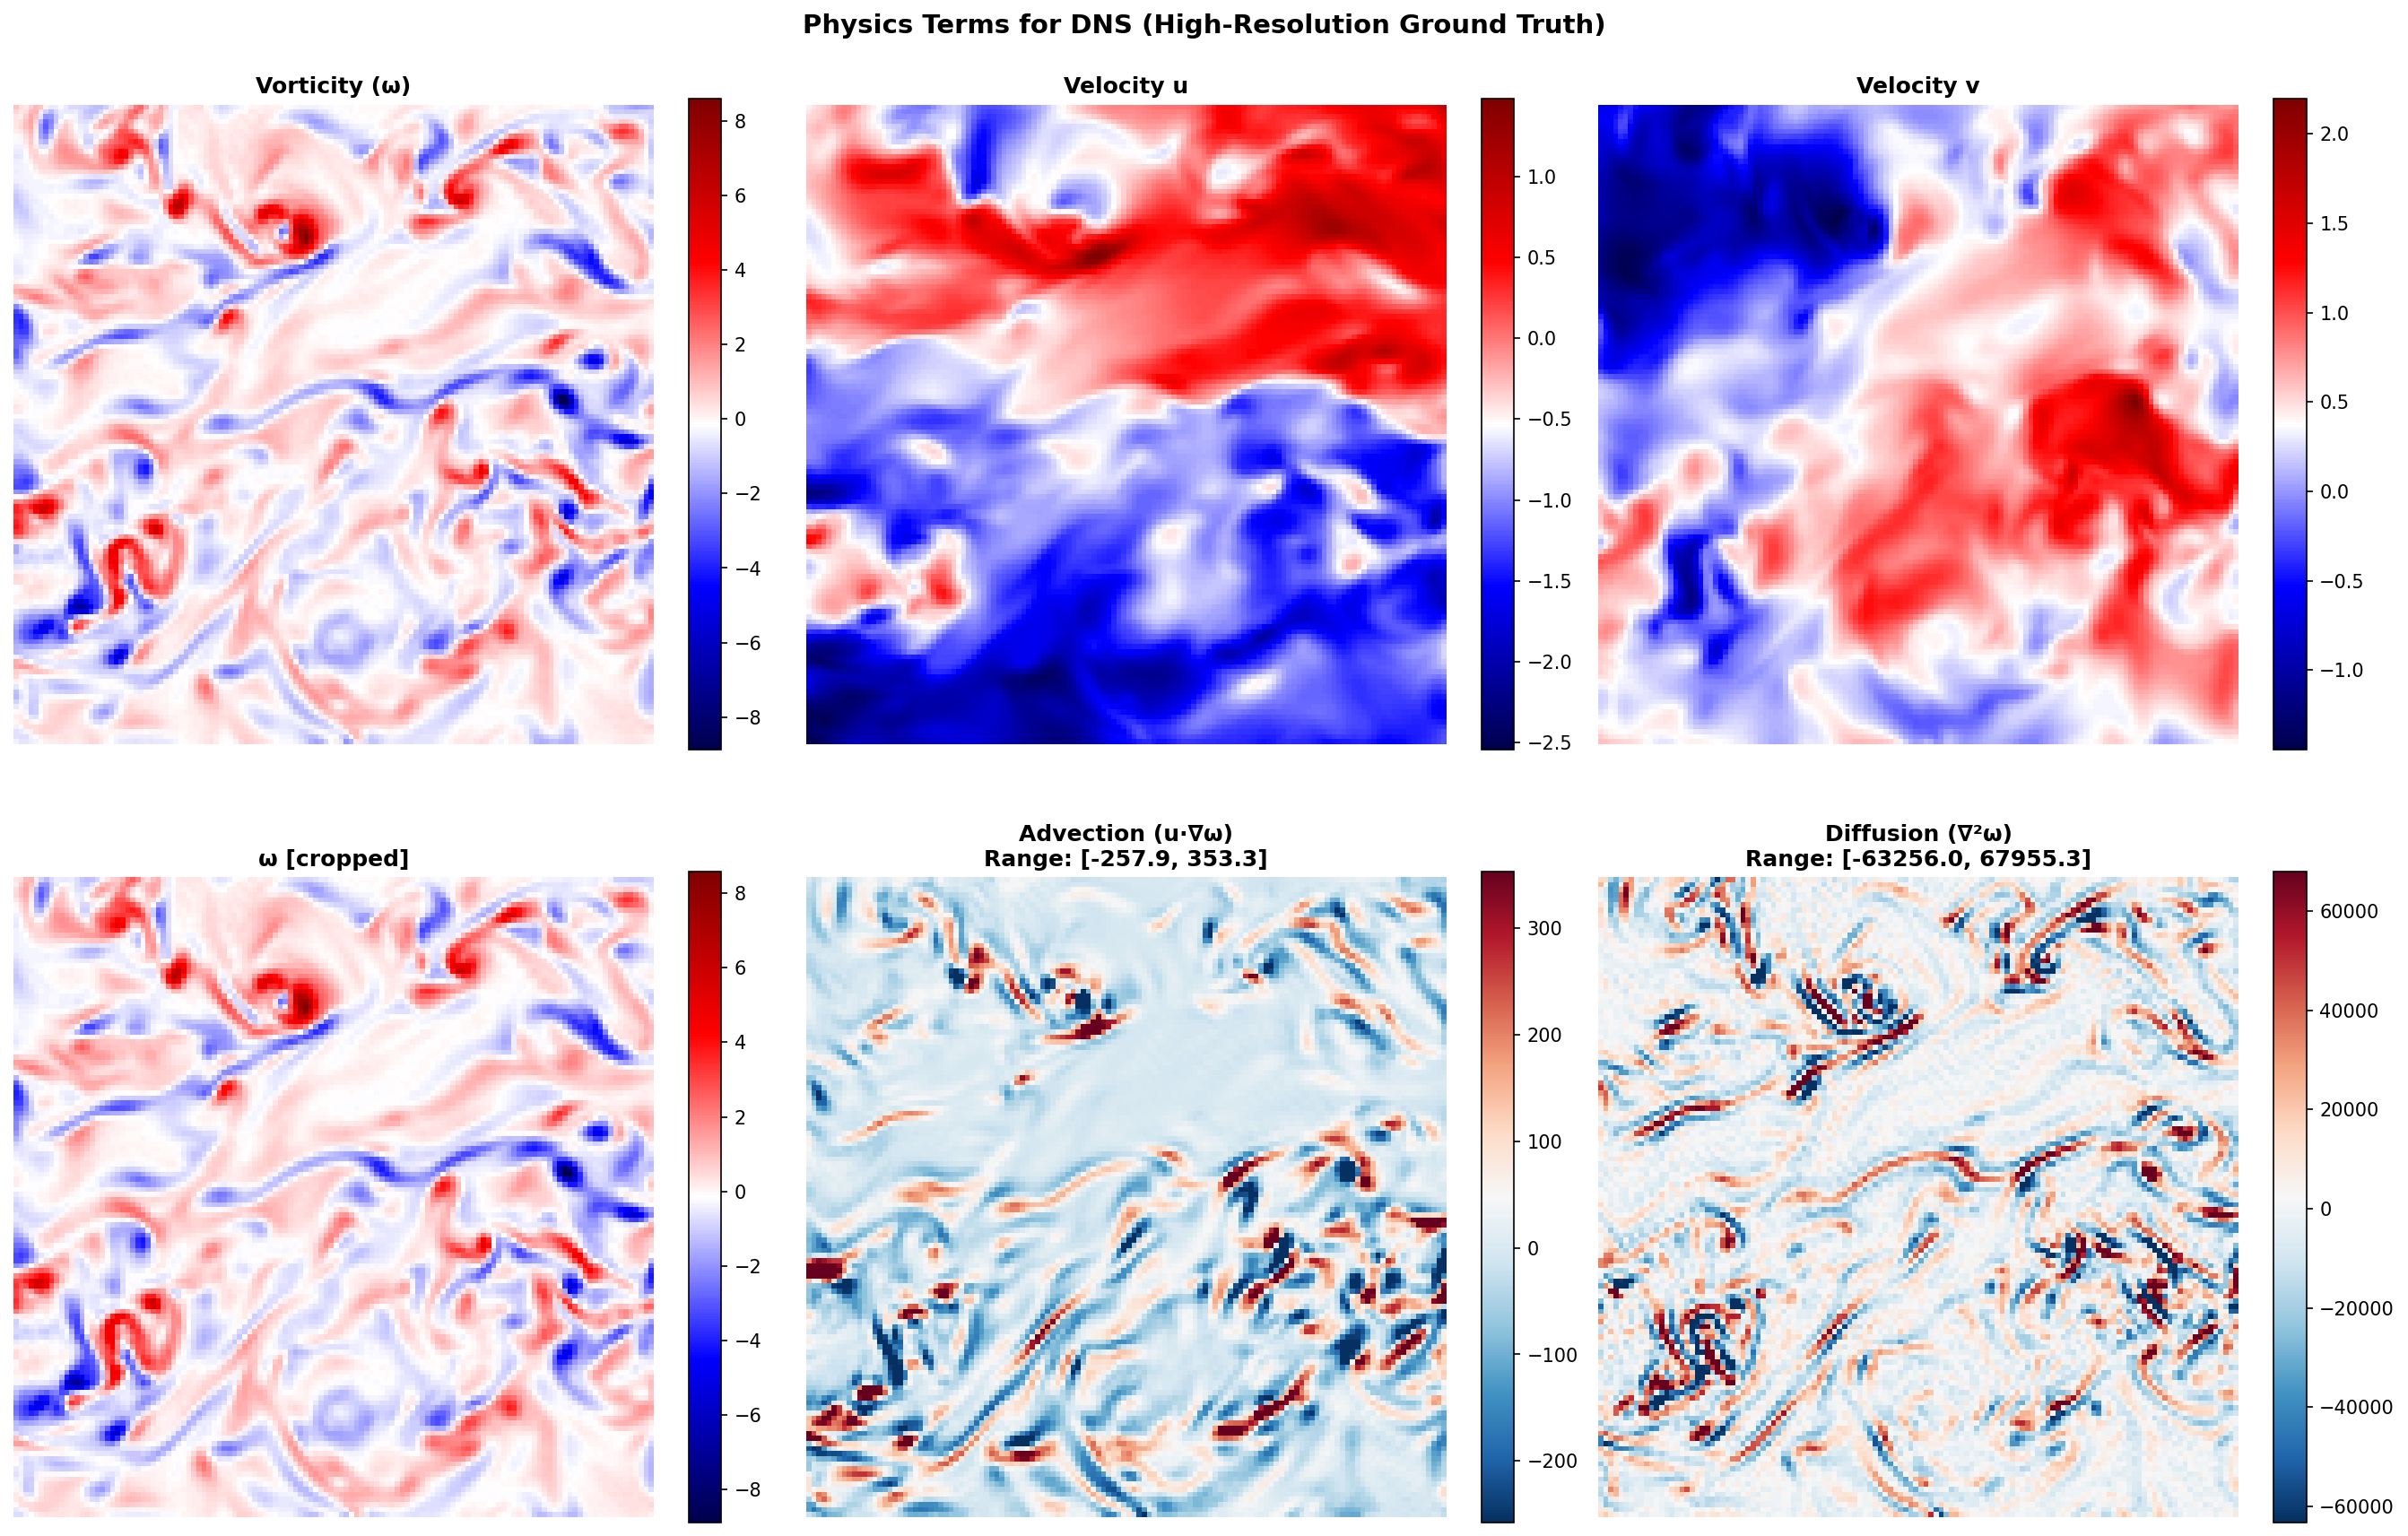


✓ Saved: /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_20251120_111621/plots/01b_physics_terms_sample.png


In [6]:
# ...existing code...
# Visualize sample training pairs
n_samples = 3
fig, axes = plt.subplots(n_samples, 3, figsize=(15, 12))

# --------------------------------------"-------------------------------
# Colorbar limits: set CB_VMIN and CB_VMAX to desired values (or None to auto)
# ---------------------------------------------------------------------
# Examples:
#   CB_VMIN, CB_VMAX = -1.0, 1.0   # fixed symmetric range
#   CB_VMIN, CB_VMAX = 0.0, 2.0    # fixed positive range
#   CB_VMIN, CB_VMAX = None, None  # automatic (use HR sample min/max)
CB_VMIN, CB_VMAX = -5, 5

# determine fallback limits from a representative HR sample if available
if CB_VMIN is None or CB_VMAX is None:
    try:
        # hr_sample exists earlier in the notebook; use it if present
        _min = float(hr_sample.min())
        _max = float(hr_sample.max())
    except NameError:
        # fallback: will set per-sample limits later if needed
        _min, _max = None, None

# Use computed fallbacks to create final cb_vmin/cb_vmax (None stays None)
cb_vmin = CB_VMIN if CB_VMIN is not None else _min
cb_vmax = CB_VMAX if CB_VMAX is not None else _max
# ---------------------------------------------------------------------

for row in range(n_samples):
    # Get a sample from training set
    if USE_PHYSICS_DATASET:
        sample = train_dataset[row * 10]
        lr = sample['lr_omega']
        hr = sample['hr_omega']
    else:
        lr, hr = train_dataset[row * 10]
    
    # If temporal stacking, show only the last frame (current time)
    if lr.shape[0] > 1:
        lr_vis = lr[-1].numpy()  # Last frame
    else:
        lr_vis = lr[0].numpy()
    
    hr_vis = hr.numpy()
    
    # If per-sample fallback needed (no hr_sample available earlier), set here
    if cb_vmin is None or cb_vmax is None:
        sample_min = float(min(lr_vis.min(), hr_vis.min()))
        sample_max = float(max(lr_vis.max(), hr_vis.max()))
        _cb_vmin = cb_vmin if cb_vmin is not None else sample_min
        _cb_vmax = cb_vmax if cb_vmax is not None else sample_max
    else:
        _cb_vmin, _cb_vmax = cb_vmin, cb_vmax

    # Upsample LR for visualization
    lr_upsampled = F.interpolate(
        torch.from_numpy(lr_vis).unsqueeze(0).unsqueeze(0),
        size=(HR_SIZE, HR_SIZE),
        mode='bilinear',
        align_corners=False
    ).squeeze().numpy()
    
    CMAP = 'seismic'  # Colormap for visualization
    # Plot LR (use the same vmin/vmax for consistent colorbar scaling)
    im0 = axes[row, 0].imshow(lr_vis.T, cmap=CMAP, origin='lower', vmin=_cb_vmin, vmax=_cb_vmax)
    axes[row, 0].set_title(f'LR ({LR_SIZE}×{LR_SIZE})', fontsize=10, fontweight='bold')
    axes[row, 0].axis('off')
    plt.colorbar(im0, ax=axes[row, 0], fraction=0.046)
    
    # Plot LR upsampled
    im1 = axes[row, 1].imshow(lr_upsampled.T, cmap=CMAP, origin='lower', vmin=_cb_vmin, vmax=_cb_vmax)
    axes[row, 1].set_title('LR Upsampled (bilinear)', fontsize=10, fontweight='bold')
    axes[row, 1].axis('off')
    plt.colorbar(im1, ax=axes[row, 1], fraction=0.046)
    
    # Plot HR target
    im2 = axes[row, 2].imshow(hr_vis.T, cmap=CMAP, origin='lower', vmin=_cb_vmin, vmax=_cb_vmax)
    axes[row, 2].set_title(f'HR Target ({HR_SIZE}×{HR_SIZE})', fontsize=10, fontweight='bold')
    axes[row, 2].axis('off')
    plt.colorbar(im2, ax=axes[row, 2], fraction=0.046)

dataset_type = "MultiFieldDataset (physics-informed)" if USE_PHYSICS_DATASET else "TemporalStackDataset"
plt.suptitle(f'Sample Training Pairs - {dataset_type}', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_sample_lr_hr_pairs.png', bbox_inches='tight', dpi=150)
plt.show()
print(f"✓ Figure saved: {FIGURES_DIR / '01_sample_lr_hr_pairs.png'}")
print(f"  LR input shape: ({N_FRAMES}, {LR_SIZE}, {LR_SIZE})")
print(f"  HR target shape: ({HR_SIZE}, {HR_SIZE})")
print(f"  Training pairs: {LR_SIZE}×{LR_SIZE} → {HR_SIZE}×{HR_SIZE}")
print(f"  Dataset type: {dataset_type}")


# =============================================================================
# Physics Terms Visualization (Sample Data)
# =============================================================================
if USE_PHYSICS_DATASET:
    print("="*70)
    print("PHYSICS TERMS ANALYSIS (Sample Training Data)")
    print("="*70)

    # Get a sample with all fields
    sample = train_dataset[0]
    hr_ux_sample = sample['hr_ux'].numpy()
    hr_uy_sample = sample['hr_uy'].numpy()
    hr_omega_sample = sample['hr_omega'].numpy()

    # Compute advection term: u·∇ω
    def compute_advection_term(u, v, omega, dx, dy):
        u_t = torch.from_numpy(u).unsqueeze(0) if isinstance(u, np.ndarray) else u
        v_t = torch.from_numpy(v).unsqueeze(0) if isinstance(v, np.ndarray) else v
        omega_t = torch.from_numpy(omega).unsqueeze(0) if isinstance(omega, np.ndarray) else omega

        if u_t.dim() == 4:
            u_t, v_t, omega_t = u_t.squeeze(1), v_t.squeeze(1), omega_t.squeeze(1)

        domega_dx = (omega_t[:, :, 2:] - omega_t[:, :, :-2]) / (2 * dx)
        domega_dy = (omega_t[:, 2:, :] - omega_t[:, :-2, :]) / (2 * dy)

        u_c = u_t[:, 1:-1, 1:-1]
        v_c = v_t[:, 1:-1, 1:-1]
        domega_dx_c = domega_dx[:, 1:-1, :]
        domega_dy_c = domega_dy[:, :, 1:-1]

        result = u_c * domega_dx_c + v_c * domega_dy_c
        return result.squeeze(0).numpy() if hasattr(result, 'numpy') else result.squeeze(0)

    # Compute diffusion term: ∇²ω
    def compute_diffusion_term(omega, dx, dy):
        omega_t = torch.from_numpy(omega).unsqueeze(0) if isinstance(omega, np.ndarray) else omega

        if omega_t.dim() == 4:
            omega_t = omega_t.squeeze(1)

        d2omega_dx2 = (omega_t[:, :, 2:] - 2*omega_t[:, :, 1:-1] + omega_t[:, :, :-2]) / (dx**2)
        d2omega_dy2 = (omega_t[:, 2:, :] - 2*omega_t[:, 1:-1, :] + omega_t[:, :-2, :]) / (dy**2)

        d2omega_dx2_c = d2omega_dx2[:, 1:-1, :]
        d2omega_dy2_c = d2omega_dy2[:, :, 1:-1]

        result = d2omega_dx2_c + d2omega_dy2_c
        return result.squeeze(0).numpy() if hasattr(result, 'numpy') else result.squeeze(0)

    # Compute physics terms
    advection = compute_advection_term(hr_ux_sample, hr_uy_sample, hr_omega_sample, dx, dy)
    diffusion = compute_diffusion_term(hr_omega_sample, dx, dy)
    omega_cropped = hr_omega_sample[1:-1, 1:-1]

    print(f"\nField statistics (normalized):")
    print(f"  Vorticity ω:       [{hr_omega_sample.min():>10.3f}, {hr_omega_sample.max():>10.3f}], std={hr_omega_sample.std():.3f}")
    print(f"  Advection (u·∇ω):  [{advection.min():>10.3f}, {advection.max():>10.3f}], std={advection.std():.3f}")
    print(f"  Diffusion (∇²ω):   [{diffusion.min():>10.3f}, {diffusion.max():>10.3f}], std={diffusion.std():.3f}")

    # Estimate proper loss weights
    advection_mse = np.mean(advection ** 2)
    diffusion_mse = np.mean(diffusion ** 2)
    omega_mse = np.mean(omega_cropped ** 2)

    print(f"\n{'='*70}")
    print("PHYSICS LOSS SCALE ESTIMATE")
    print("="*70)
    print(f"Mean squared values:")
    print(f"  E(ω²):       {omega_mse:.2e}")
    print(f"  E((u·∇ω)²):  {advection_mse:.2e}")
    print(f"  E((∇²ω)²):   {diffusion_mse:.2e}")
    print(f"\nTo match vorticity loss scale, use:")
    print(f"  lambda_adv  ≈ {omega_mse / advection_mse:.2e}")
    print(f"  lambda_diff ≈ {omega_mse / diffusion_mse:.2e}")

    # Visualize
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    # Row 1: Fields
    im0 = axes[0, 0].imshow(hr_omega_sample.T, cmap='seismic', origin='lower')
    axes[0, 0].set_title('Vorticity (ω)', fontsize=12, fontweight='bold')
    axes[0, 0].axis('off')
    plt.colorbar(im0, ax=axes[0, 0], fraction=0.046)

    im1 = axes[0, 1].imshow(hr_ux_sample.T, cmap='seismic', origin='lower')
    axes[0, 1].set_title('Velocity u', fontsize=12, fontweight='bold')
    axes[0, 1].axis('off')
    plt.colorbar(im1, ax=axes[0, 1], fraction=0.046)

    im2 = axes[0, 2].imshow(hr_uy_sample.T, cmap='seismic', origin='lower')
    axes[0, 2].set_title('Velocity v', fontsize=12, fontweight='bold')
    axes[0, 2].axis('off')
    plt.colorbar(im2, ax=axes[0, 2], fraction=0.046)

    # Row 2: Physics terms (use percentile clipping for better visualization)
    adv_vmin, adv_vmax = np.percentile(advection, [1, 99])
    diff_vmin, diff_vmax = np.percentile(diffusion, [1, 99])

    im3 = axes[1, 0].imshow(omega_cropped.T, cmap='seismic', origin='lower')
    axes[1, 0].set_title('ω [cropped]', fontsize=12, fontweight='bold')
    axes[1, 0].axis('off')
    plt.colorbar(im3, ax=axes[1, 0], fraction=0.046)

    im4 = axes[1, 1].imshow(advection.T, cmap='RdBu_r', origin='lower',
                            vmin=adv_vmin, vmax=adv_vmax)
    axes[1, 1].set_title(f'Advection (u·∇ω)\nRange: [{adv_vmin:.1f}, {adv_vmax:.1f}]',
                          fontsize=12, fontweight='bold')
    axes[1, 1].axis('off')
    plt.colorbar(im4, ax=axes[1, 1], fraction=0.046)

    im5 = axes[1, 2].imshow(diffusion.T, cmap='RdBu_r', origin='lower',
                            vmin=diff_vmin, vmax=diff_vmax)
    axes[1, 2].set_title(f'Diffusion (∇²ω)\nRange: [{diff_vmin:.1f}, {diff_vmax:.1f}]',
                          fontsize=12, fontweight='bold')
    axes[1, 2].axis('off')
    plt.colorbar(im5, ax=axes[1, 2], fraction=0.046)

    plt.suptitle('Physics Terms for DNS (High-Resolution Ground Truth)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '01b_physics_terms_sample.png', bbox_inches='tight', dpi=150)
    plt.show()
    print(f"\n✓ Saved: {FIGURES_DIR / '01b_physics_terms_sample.png'}")

## Data Augmentation Sanity Check

In [ ]:
# =============================================================================
# Visualize Data Augmentation Transformations
# =============================================================================

if config['data']['augmentation']['enabled']:
    print("="*70)
    print("DATA AUGMENTATION SANITY CHECK")
    print("="*70)
    print(f"\nEnabled augmentations:")
    aug_cfg = config['data']['augmentation']
    print(f"  Cyclic shift: {aug_cfg.get('cyclic_shift', False)}")
    print(f"  180° rotation: {aug_cfg.get('rot180', False)}")
    print(f"  Flip X: {aug_cfg.get('flipx', False)}")
    print(f"  Flip Y: {aug_cfg.get('flipy', False)}")
    print(f"  90° rotation: {aug_cfg.get('rot90', False)}")
    if 'sign_maps' in aug_cfg:
        print(f"  Sign maps: {aug_cfg['sign_maps']}")
    
    # Get multiple augmented versions of the same sample
    # We'll manually call the dataset multiple times to get different augmentations
    print(f"\nGenerating multiple augmented versions of the same snapshot...")
    
    # Get the base sample (index 0) multiple times - each time will apply random augmentation
    n_aug_samples = 6  # Original + 5 augmented versions
    aug_samples = []
    
    for i in range(n_aug_samples):
        if USE_PHYSICS_DATASET:
            sample = train_dataset[0]  # Get first sample with random augmentation
            lr = sample['lr_omega']
            hr = sample['hr_omega']
        else:
            lr, hr = train_dataset[0]  # Get first sample with random augmentation
        
        # Extract for visualization
        if lr.shape[0] > 1:
            lr_vis = lr[-1].numpy()
        else:
            lr_vis = lr[0].numpy()
        hr_vis = hr.numpy()
        
        aug_samples.append((lr_vis, hr_vis))
    
    # Create visualization with 2 rows: LR and HR
    fig, axes = plt.subplots(2, n_aug_samples, figsize=(4*n_aug_samples, 8))
    
    # Use consistent colorbar limits
    all_lr = [s[0] for s in aug_samples]
    all_hr = [s[1] for s in aug_samples]
    vmin_lr = min(s.min() for s in all_lr)
    vmax_lr = max(s.max() for s in all_lr)
    vmin_hr = min(s.min() for s in all_hr)
    vmax_hr = max(s.max() for s in all_hr)
    
    CMAP = 'seismic'
    
    for col, (lr_vis, hr_vis) in enumerate(aug_samples):
        # Plot LR
        im0 = axes[0, col].imshow(lr_vis.T, cmap=CMAP, origin='lower', vmin=vmin_lr, vmax=vmax_lr)
        title = 'Original' if col == 0 else f'Aug {col}'
        axes[0, col].set_title(f'{title}\nLR ({LR_SIZE}×{LR_SIZE})', fontsize=10, fontweight='bold')
        axes[0, col].axis('off')
        plt.colorbar(im0, ax=axes[0, col], fraction=0.046)
        
        # Plot HR
        im1 = axes[1, col].imshow(hr_vis.T, cmap=CMAP, origin='lower', vmin=vmin_hr, vmax=vmax_hr)
        axes[1, col].set_title(f'{title}\nHR ({HR_SIZE}×{HR_SIZE})', fontsize=10, fontweight='bold')
        axes[1, col].axis('off')
        plt.colorbar(im1, ax=axes[1, col], fraction=0.046)
    
    plt.suptitle('Data Augmentation: Multiple Random Transforms of Same Snapshot', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '01c_augmentation_samples.png', bbox_inches='tight', dpi=150)
    plt.show()
    print(f"\n✓ Saved: {FIGURES_DIR / '01c_augmentation_samples.png'}")
    
    # ==========================================================================
    # DETAILED AUGMENTATION BREAKDOWN: Show specific transforms
    # ==========================================================================
    print(f"\n{'='*70}")
    print("DETAILED AUGMENTATION BREAKDOWN")
    print("="*70)
    print("Showing specific augmentation transforms applied to the same snapshot\n")
    
    # Temporarily disable augmentation to get the original
    train_dataset.transform_config['enabled'] = False
    if USE_PHYSICS_DATASET:
        sample_orig = train_dataset[0]
        lr_orig = sample_orig['lr_omega']
        hr_orig = sample_orig['hr_omega']
    else:
        lr_orig, hr_orig = train_dataset[0]
    
    if lr_orig.shape[0] > 1:
        lr_orig_vis = lr_orig[-1].numpy()
    else:
        lr_orig_vis = lr_orig[0].numpy()
    hr_orig_vis = hr_orig.numpy()
    
    # Re-enable augmentation
    train_dataset.transform_config['enabled'] = True
    
    # Manually apply specific transforms
    transforms_to_show = []
    
    # 1. Original (no transform)
    transforms_to_show.append(('Original', lr_orig_vis.copy(), hr_orig_vis.copy()))
    
    # 2. Cyclic shift (simulate by rolling)
    if aug_cfg.get('cyclic_shift', False):
        shift_x, shift_y = 30, 30  # Example shift
        lr_shifted = np.roll(np.roll(lr_orig_vis, shift_x, axis=0), shift_y, axis=1)
        hr_shifted = np.roll(np.roll(hr_orig_vis, shift_x, axis=0), shift_y, axis=1)
        transforms_to_show.append(('Cyclic Shift\n(+30, +30)', lr_shifted, hr_shifted))
    
    # 3. 180° rotation
    if aug_cfg.get('rot180', False):
        lr_rot180 = np.rot90(lr_orig_vis, k=2)
        hr_rot180 = np.rot90(hr_orig_vis, k=2)
        transforms_to_show.append(('Rotation 180°', lr_rot180, hr_rot180))
    
    # 4. Flip X (vertical flip)
    if aug_cfg.get('flipx', False):
        lr_flipx = np.flip(lr_orig_vis, axis=0).copy()
        hr_flipx = np.flip(hr_orig_vis, axis=0).copy()
        # Apply sign map if defined
        if 'sign_maps' in aug_cfg and 'omega_z' in aug_cfg['sign_maps']:
            sign = aug_cfg['sign_maps']['omega_z'].get('flipx', 1)
            if sign == -1:
                lr_flipx *= -1
                hr_flipx *= -1
        transforms_to_show.append(('Flip X\n(vertical)', lr_flipx, hr_flipx))
    
    # 5. Flip Y (horizontal flip)
    if aug_cfg.get('flipy', False):
        lr_flipy = np.flip(lr_orig_vis, axis=1).copy()
        hr_flipy = np.flip(hr_orig_vis, axis=1).copy()
        # Apply sign map if defined
        if 'sign_maps' in aug_cfg and 'omega_z' in aug_cfg['sign_maps']:
            sign = aug_cfg['sign_maps']['omega_z'].get('flipy', 1)
            if sign == -1:
                lr_flipy *= -1
                hr_flipy *= -1
        transforms_to_show.append(('Flip Y\n(horizontal)', lr_flipy, hr_flipy))
    
    # Create detailed visualization
    n_transforms = len(transforms_to_show)
    fig, axes = plt.subplots(2, n_transforms, figsize=(4.5*n_transforms, 9))
    
    # Ensure axes is 2D
    if n_transforms == 1:
        axes = axes.reshape(2, 1)
    
    # Use consistent colorbar limits for fair comparison
    all_lr_detail = [t[1] for t in transforms_to_show]
    all_hr_detail = [t[2] for t in transforms_to_show]
    vmin_lr = min(s.min() for s in all_lr_detail)
    vmax_lr = max(s.max() for s in all_lr_detail)
    vmin_hr = min(s.min() for s in all_hr_detail)
    vmax_hr = max(s.max() for s in all_hr_detail)
    
    for col, (transform_name, lr_vis, hr_vis) in enumerate(transforms_to_show):
        # Plot LR
        im0 = axes[0, col].imshow(lr_vis.T, cmap=CMAP, origin='lower', vmin=vmin_lr, vmax=vmax_lr)
        axes[0, col].set_title(f'{transform_name}\nLR ({LR_SIZE}×{LR_SIZE})', 
                               fontsize=11, fontweight='bold')
        axes[0, col].axis('off')
        plt.colorbar(im0, ax=axes[0, col], fraction=0.046)
        
        # Plot HR
        im1 = axes[1, col].imshow(hr_vis.T, cmap=CMAP, origin='lower', vmin=vmin_hr, vmax=vmax_hr)
        axes[1, col].set_title(f'{transform_name}\nHR ({HR_SIZE}×{HR_SIZE})', 
                               fontsize=11, fontweight='bold')
        axes[1, col].axis('off')
        plt.colorbar(im1, ax=axes[1, col], fraction=0.046)
    
    plt.suptitle('Specific Data Augmentation Transforms (Same Snapshot)', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '01d_augmentation_breakdown.png', bbox_inches='tight', dpi=150)
    plt.show()
    print(f"✓ Saved: {FIGURES_DIR / '01d_augmentation_breakdown.png'}")
    
    print(f"\n{'='*70}")
    print("AUGMENTATION SANITY CHECK COMPLETE")
    print("="*70)
    print(f"Verify that:")
    print(f"  1. Augmented samples show realistic variations")
    print(f"  2. Sign maps are correctly applied for flips")
    print(f"  3. Cyclic shifts preserve periodicity")
    print(f"  4. LR and HR pairs remain consistent after transforms")
    print(f"{'='*70}")
    
else:
    print(f"\n{'='*70}")
    print("Data augmentation is DISABLED in config")
    print("="*70)
    print("Skipping augmentation visualization.")

## Field Statistics & PDFs

In [ ]:
from pathlib import Path
FIGURES_DATA_DIR = FIGURES_DIR / 'data_inspection'
FIGURES_DATA_DIR.mkdir(parents=True, exist_ok=True)

mean_series = hr_data.mean(axis=(1, 2))
std_series = hr_data.std(axis=(1, 2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(mean_series, label='Mean')
axes[0].plot(std_series, label='Std')
axes[0].set_title('Snapshot Statistics', fontweight='bold')
axes[0].set_xlabel('Snapshot index')
axes[0].legend()
axes[0].grid(alpha=0.3)

centers, pdf_vals = pdf_from_field(hr_data[train_idx], bins=120)
axes[1].plot(centers, pdf_vals, lw=2)
axes[1].set_title('PDF of Training HR Samples', fontweight='bold')
axes[1].set_xlabel('Value')
axes[1].set_ylabel('Probability density')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DATA_DIR / '02_field_stats.png', bbox_inches='tight', dpi=150)
plt.show()
print(f"✓ Saved field statistics figure to {FIGURES_DATA_DIR}")

## Summary

In [ ]:
print('=' * 70)
print('DATA INSPECTION SUMMARY')
print('=' * 70)
print(f"Dataset:          {h5_path}")
print(f"Snapshots:        {hr_data.shape[0]}")
print(f"Resolution:       {hr_data.shape[1]} x {hr_data.shape[2]}")
print(f"Component:        {component}")
print(f"Physics dataset:  {USE_PHYSICS_DATASET}")
print(f"Train/Val/Test:   {len(train_idx)} / {len(val_idx)} / {len(test_idx)} snapshots")
print(f"LR size:          {LR_SIZE}")
print(f"HR size:          {HR_SIZE}")
print(f"Figures saved to: {FIGURES_DIR}")
print('=' * 70)